# Handwritten Character Recognition (MNIST) — CodeAlpha ML Internship, Task 3

CNN-based recognition of handwritten digits using Keras.

**Pipeline:** load and preprocess, compare three CNNs, evaluate properly (confusion matrix, per-class metrics, misclassified examples), then predict on your own handwriting.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report

keras.utils.set_random_seed(42)  # reproducible results

### 1. Load and explore the data

In [6]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (60000, 28, 28)  Test: (10000, 28, 28)


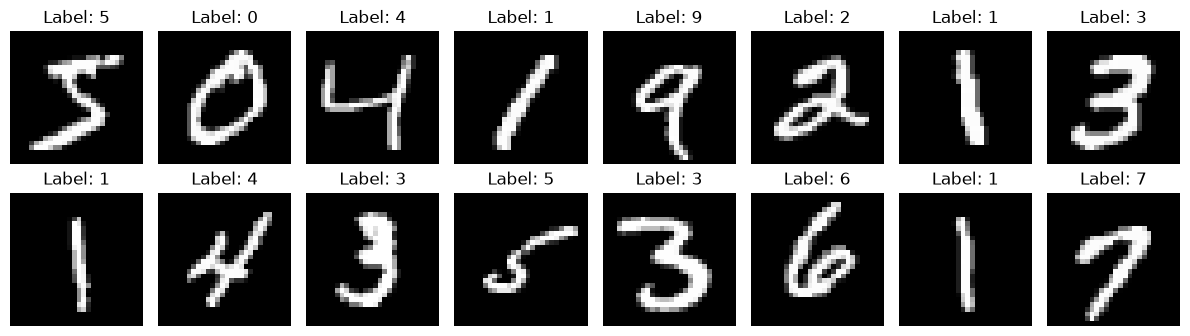

In [9]:
fig, axes = plt.subplots(2, 8, figsize=(12, 3.5))
for ax, img, lbl in zip(axes.ravel(), X_train, y_train):
    ax.imshow(img, cmap="gray")
    ax.set_title(f"Label: {lbl}")
    ax.axis("off")
plt.tight_layout()
plt.show()

### 2. Preprocess
Normalize to [0, 1] and add the channel dimension that Conv2D expects: `(N, 28, 28, 1)`.

In [10]:
X_train = (X_train / 255.0).astype("float32").reshape(-1, 28, 28, 1)
X_test  = (X_test  / 255.0).astype("float32").reshape(-1, 28, 28, 1)
print(X_train.shape, X_test.shape)

(60000, 28, 28, 1) (10000, 28, 28, 1)


## 3. Models

We compare three CNNs. Model selection uses a **validation split** taken from the training data, so the test set stays untouched until the final evaluation.

1. `baseline`: one Conv block
2. `deeper`: two Conv blocks
3. `regularized`: the deeper model plus augmentation and Dropout

In [21]:
def build_baseline():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="baseline")


def build_deeper():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dense(64, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ], name="deeper")


def build_regularized():
    return keras.Sequential([
        keras.Input(shape=(28, 28, 1)),
        # Augmentation layers are only active during training
        layers.RandomRotation(0.05),
        layers.RandomTranslation(0.1, 0.1),
        layers.Conv2D(32, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Flatten(),
        layers.Dropout(0.4),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(10, activation="softmax"),
    ], name="regularized")

In [30]:
def train(model, epochs=30):
    model.compile(
        optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
    return model.fit(
        X_train, y_train,
        validation_split=0.1,
        epochs=epochs,
        batch_size=128,
        callbacks=[early_stop],
        verbose=2,
    )


models, histories = {}, {}
for builder in (build_baseline, build_deeper, build_regularized):
    m = builder()
    print(f"\n=== Training {m.name} ===")
    histories[m.name] = train(m)
    models[m.name] = m


=== Training baseline ===
Epoch 1/30
422/422 - 14s - 32ms/step - accuracy: 0.9237 - loss: 0.2730 - val_accuracy: 0.9758 - val_loss: 0.0910
Epoch 2/30
422/422 - 10s - 23ms/step - accuracy: 0.9747 - loss: 0.0872 - val_accuracy: 0.9830 - val_loss: 0.0633
Epoch 3/30
422/422 - 10s - 24ms/step - accuracy: 0.9820 - loss: 0.0593 - val_accuracy: 0.9842 - val_loss: 0.0571
Epoch 4/30
422/422 - 10s - 23ms/step - accuracy: 0.9869 - loss: 0.0457 - val_accuracy: 0.9855 - val_loss: 0.0552
Epoch 5/30
422/422 - 9s - 22ms/step - accuracy: 0.9899 - loss: 0.0359 - val_accuracy: 0.9855 - val_loss: 0.0568
Epoch 6/30
422/422 - 10s - 23ms/step - accuracy: 0.9920 - loss: 0.0284 - val_accuracy: 0.9850 - val_loss: 0.0584
Epoch 7/30
422/422 - 10s - 23ms/step - accuracy: 0.9941 - loss: 0.0226 - val_accuracy: 0.9852 - val_loss: 0.0591

=== Training deeper ===
Epoch 1/30
422/422 - 20s - 48ms/step - accuracy: 0.9278 - loss: 0.2434 - val_accuracy: 0.9803 - val_loss: 0.0678
Epoch 2/30
422/422 - 18s - 42ms/step - accura

### 4. Compare models (validation set)


,epochs run,best val accuracy,best val loss
model,,,
baseline,7,0.9855,0.0552
deeper,8,0.9902,0.0386
regularized,9,0.9895,0.0346


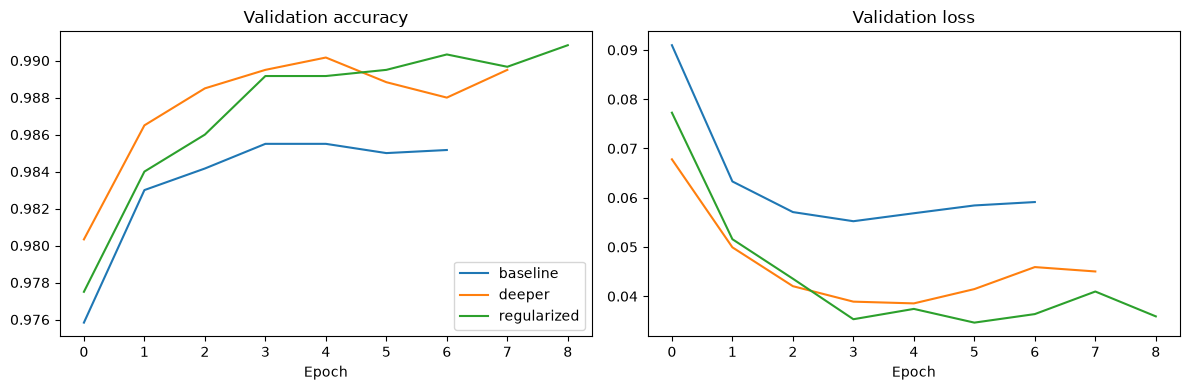

In [40]:
import pandas as pd

rows = []
for name, h in histories.items():
    best = int(np.argmin(h.history["val_loss"]))
    rows.append({
        "model": name,
        "epochs run": len(h.history["loss"]),
        "best val accuracy": round(h.history["val_accuracy"][best], 4),
        "best val loss": round(h.history["val_loss"][best], 4),
    })
comparison = pd.DataFrame(rows).set_index("model")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    axes[0].plot(h.history["val_accuracy"], label=name)
    axes[1].plot(h.history["val_loss"], label=name)
axes[0].set(title="Validation accuracy", xlabel="Epoch")
axes[1].set(title="Validation loss", xlabel="Epoch")
axes[0].legend()
plt.tight_layout()
plt.show()

## 5. Final evaluation on the test set
The best model is chosen by validation loss above, then evaluated once on the test set.

In [43]:
best_name = comparison["best val loss"].idxmin()
best_model = models[best_name]
print("Selected model:", best_name)

test_loss, test_acc = best_model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}   Test loss: {test_loss:.4f}")

y_prob = best_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

Selected model: regularized
Test accuracy: 0.9902   Test loss: 0.0284


### Confusion matrix and per-class metrics

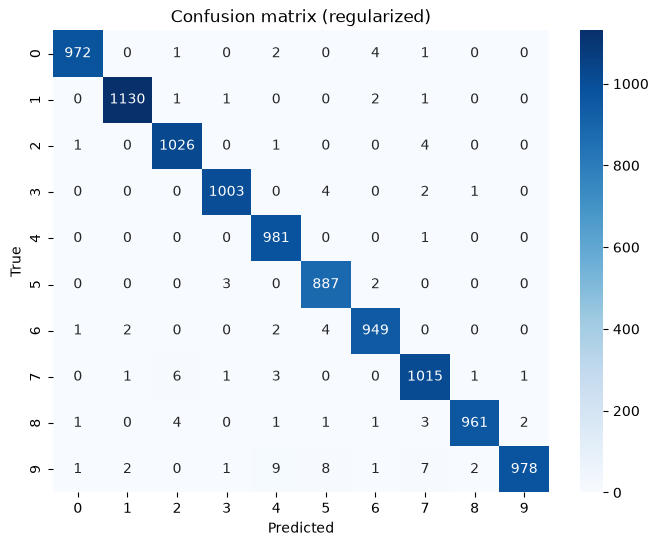

              precision    recall  f1-score   support

           0     0.9959    0.9918    0.9939       980
           1     0.9956    0.9956    0.9956      1135
           2     0.9884    0.9942    0.9913      1032
           3     0.9941    0.9931    0.9936      1010
           4     0.9820    0.9990    0.9904       982
           5     0.9812    0.9944    0.9878       892
           6     0.9896    0.9906    0.9901       958
           7     0.9816    0.9874    0.9845      1028
           8     0.9959    0.9867    0.9912       974
           9     0.9969    0.9693    0.9829      1009

    accuracy                         0.9902     10000
   macro avg     0.9901    0.9902    0.9901     10000
weighted avg     0.9903    0.9902    0.9902     10000



In [44]:
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"Confusion matrix ({best_name})")
plt.show()

print(classification_report(y_test, y_pred, digits=4))

### Misclassified examples

98 misclassified out of 10000


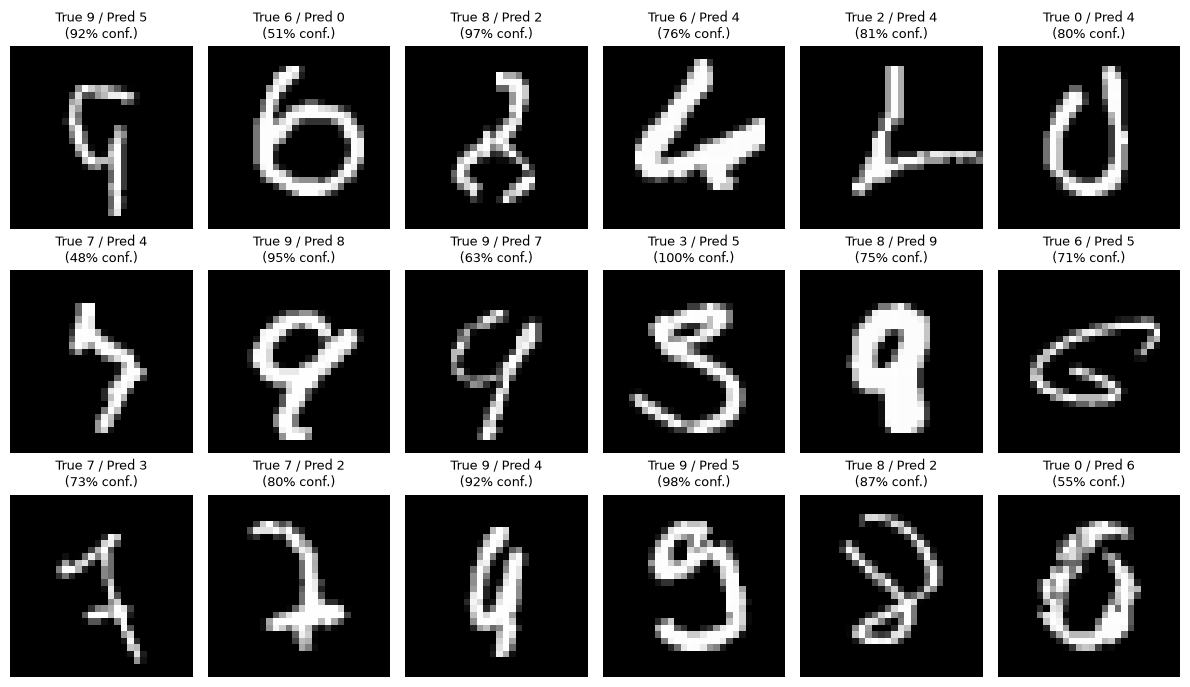

In [46]:
wrong = np.where(y_pred != y_test)[0]
print(f"{len(wrong)} misclassified out of {len(y_test)}")

fig, axes = plt.subplots(3, 6, figsize=(12, 7))
for ax, i in zip(axes.ravel(), wrong[:18]):
    ax.imshow(X_test[i].squeeze(), cmap="gray")
    ax.set_title(f"True {y_test[i]} / Pred {y_pred[i]}\n({y_prob[i].max():.0%} conf.)", fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 6. Save the model

In [47]:
best_model.save("mnist_cnn.keras")
print("Saved mnist_cnn.keras")

Saved mnist_cnn.keras


## 7. Predict on your own handwriting

Write one digit in **dark ink on white paper** (or draw it in any paint app), take a photo or screenshot, then set `IMAGE_PATH` below.

`preprocess_image` converts it to grayscale, inverts it (MNIST is white-on-black), crops to the digit, and centers it in a 28×28 frame the way MNIST digits are.

In [58]:
import scipy.ndimage as ndi
from PIL import Image


def preprocess_image(path):
    img = Image.open(path).convert("L")
    img.thumbnail((800, 800))
    a = np.array(img).astype("float32")

    # 1. Remove uneven lighting: estimate the paper brightness and subtract it
    background = ndi.gaussian_filter(ndi.grey_closing(a, size=(25, 25)), sigma=15)
    ink = np.clip(background - a, 0, None)  # ink is darker than paper

    # 2. Keep only strong ink pixels (relative threshold, robust to lighting)
    ink = ink / (ink.max() + 1e-6)
    mask = ink > 0.35
    mask = ndi.binary_opening(mask, iterations=1) | (ink > 0.6)

    # 3. Keep the largest ink blob (the digit) and crop to it
    labels, n = ndi.label(ndi.binary_dilation(mask, iterations=6))
    if n == 0:
        raise ValueError("No digit found in the image.")
    sizes = ndi.sum(mask, labels, range(1, n + 1))
    mask = mask & (labels == 1 + int(np.argmax(sizes)))
    ys, xs = np.where(mask)
    mask = mask[ys.min():ys.max() + 1, xs.min():xs.max() + 1]

    # 4. Thicken strokes: MNIST strokes are thick, pen lines are thin
    h, w = mask.shape
    mask = ndi.binary_dilation(mask, iterations=max(2, int(max(h, w) * 0.07)))

    # 5. Resize longest side to 20px, centre by centre of mass in 28x28
    digit = Image.fromarray((mask * 255).astype("uint8"))
    digit.thumbnail((20, 20), Image.LANCZOS)
    d = np.array(digit).astype("float32")
    canvas = np.zeros((28, 28), dtype="float32")
    oy, ox = (28 - d.shape[0]) // 2, (28 - d.shape[1]) // 2
    canvas[oy:oy + d.shape[0], ox:ox + d.shape[1]] = d
    cy, cx = ndi.center_of_mass(canvas)
    canvas = ndi.shift(canvas, (14 - cy, 14 - cx), order=1)

    return np.clip(canvas / 255.0, 0, 1).reshape(1, 28, 28, 1)


def predict_image(path, model=best_model):
    x = preprocess_image(path)
    probs = model.predict(x, verbose=0)[0]
    pred = int(np.argmax(probs))

    fig, axes = plt.subplots(1, 2, figsize=(9, 3))
    axes[0].imshow(x.squeeze(), cmap="gray")
    axes[0].set_title(f"Prediction: {pred} ({probs[pred]:.0%})")
    axes[0].axis("off")
    axes[1].bar(range(10), probs)
    axes[1].set(xticks=range(10), xlabel="Digit", ylabel="Probability", title="Class probabilities")
    plt.tight_layout()
    plt.show()
    return pred


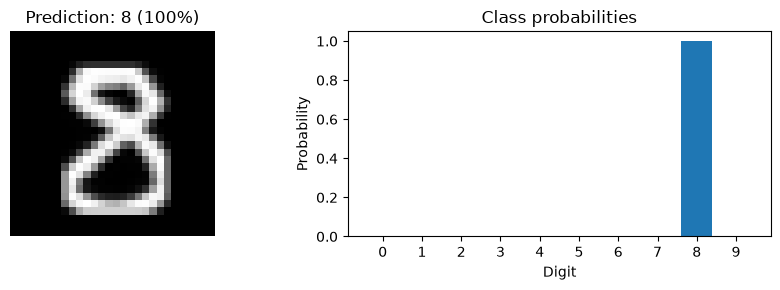

8

In [59]:
IMAGE_PATH = "my_digit1.png"
predict_image(IMAGE_PATH)

In [60]:
from pathlib import Path
import pandas as pd

SAMPLES_DIR = Path("samples")
exts = {".png", ".jpg", ".jpeg", ".webp"}
files = sorted(p for p in SAMPLES_DIR.glob("*") if p.suffix.lower() in exts)
print(f"Found {len(files)} images in {SAMPLES_DIR}/")

results, inputs = [], []
for p in files:
    try:
        x = preprocess_image(str(p))
    except ValueError as e:
        print(f"Skipped {p.name}: {e}")
        continue
    probs = best_model.predict(x, verbose=0)[0]
    pred = int(np.argmax(probs))
    true = int(p.name[0]) if p.name[0].isdigit() else None
    results.append({"file": p.name, "true": true, "predicted": pred,
                    "confidence": round(float(probs[pred]), 3),
                    "correct": (pred == true) if true is not None else None})
    inputs.append(x.squeeze())

df = pd.DataFrame(results)
display(df)

labelled = df.dropna(subset=["true"])
if len(labelled):
    print(f"Accuracy on your own digits: {labelled['correct'].mean():.0%} "
          f"({int(labelled['correct'].sum())}/{len(labelled)})")

Found 8 images in samples/


,file,true,predicted,confidence,correct
0,0_a.png,0,0,1.000,True
1,1_base.jpeg,1,1,0.828,True
2,1_plain.png,1,1,1.000,True
3,5_a.jpeg,5,5,1.000,True
4,6_a.jpeg,6,6,0.938,True
5,7_crossed.jpeg,7,7,0.958,True
6,8_crossed.jpeg,8,8,1.000,True
7,9_a.jpeg,9,9,1.000,True


Accuracy on your own digits: 100% (8/8)


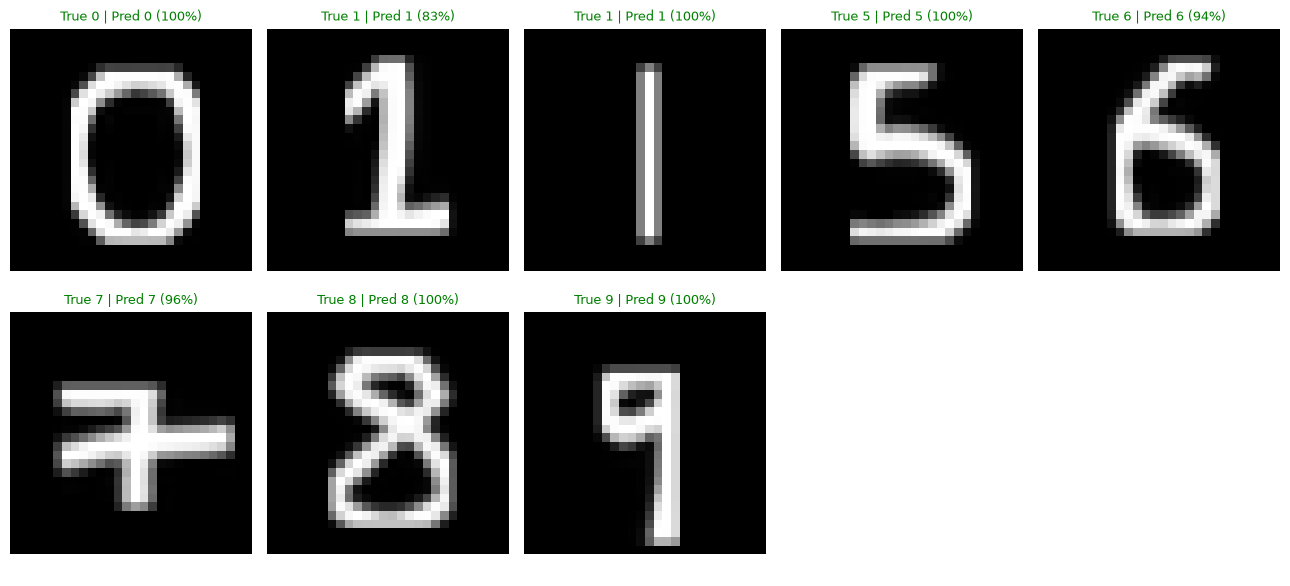

In [61]:
# Grid of what the model saw: green = correct, red = wrong
n = len(inputs)
cols = min(5, n)
rows = int(np.ceil(n / cols))
fig, axes = plt.subplots(rows, cols, figsize=(2.6 * cols, 3 * rows), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, img, (_, r) in zip(axes.ravel(), inputs, df.iterrows()):
    ax.imshow(img, cmap="gray")
    has_label = pd.notna(r["true"])
    colour = ("green" if r["correct"] else "red") if has_label else "gray"
    label = f"Pred {r['predicted']} ({r['confidence']:.0%})"
    if has_label:
        label = f"True {int(r['true'])} | " + label
    ax.set_title(label, color=colour, fontsize=9)
plt.tight_layout()
plt.show()

## Summary

Fill this in with your own numbers after running the notebook:

- Best model: `regularized` 
- Test accuracy: 0.9902
- Most-confused digit pairs: 2 and 7
- Possible extensions: EMNIST for letters, CRNN for words